# Numerical Comparison with Continuous Black-Scholes Model
Now that we have our discrete time model, we will compare it with the continuous time model with Black-Scholes.

The formula using Black-Scholes for a European Call option is:

$$C=S\Phi(d_1)-Ke^{-rT}\Phi(d_2)$$

where $d_1=\frac{\ln(S/K)+(r+\sigma^2/2)T}{\sigma\sqrt{T}}$ and $d_2=d_1-\sigma\sqrt{T}$. Note that $\Phi$ denotes the standard normal cumulative distribution function accessible using `scipy.stats.norm.cdf`. For the price of a put-option, we can use the fact that for European-style options, the price of a put option is related to the price of the call option by:

$$C-P=S-Ke^{-rT}\implies P = C-(S-Ke^{-rT})$$

For American-style options, this model will still generate the correct price EXCEPT when it comes to American put options. The reason is because American call options don't benefit from exercising early as the time-value of the option will essentially be wasted; more details at the [bottom*](#why-american-style-calls-never-benefit-from-early-exercising). However, put options are different as oppotunities where the stock price drops below the strike price can have more value than waiting.

### Import appropriate modules

In [2]:
from pathlib import Path
import sys

# Get the directory of the notebook, navigate up, and find 'src'
src_path = Path.cwd().parent / "src"

# Add to system path if it's not already there
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

# Import the other modules
import numpy as np 
import matplotlib.pyplot as plt
from scipy.special import binom

# The discrete model
from binomial_option_pricer import binomial_option_pricer, call_payoff, put_payoff

# Import the Black-Scholes Model
from black_scholes_pricer import black_scholes_price

### Input Tree Parameters

In [9]:
S = 250
K = 250
T = 1
N = 300

sigma = 0.8
r = 0.02
call = True
european = True
A = binomial_option_pricer(S=S, K=K, T=T, N=N, sigma=sigma, r=r, call=call, european=european)

### Checking the No-Arbitrage Rule

In [10]:
R = np.exp(r*T/N)
u = np.exp(sigma*np.sqrt(T/N))
d = 1/u
q = (R-d)/(u-d)

print(f"d = {d}")
print(f"R = {R}")
print(f"u = {u}")

if R <= d:
    raise ValueError("Arbitrage oppotunity (R <= d): Borrow money at the market risk-free rate and put it into the stock")
elif R >= u:
    raise ValueError("Arbitrage oppotunity (R >= u): Short-sell the stock and put that money in an investment returning the market risk-free rate")
else:
    print("No-Arbitrage Rule not violated!")


d = 0.9548624106151421
R = 1.0000666688889384
u = 1.047271302004421
No-Arbitrage Rule not violated!


### Numerical Comparison

The following code plots the convergence of the discrete-time model to the true Black-Scholes option price as the number of time-steps $N$ increases. The right plot shows the absolute error between the discrete-time option value to the true Black-Scholes option value versus the number of time-steps $N$ in a log-log plot.

Text(0, 0.5, 'Absolste Error')

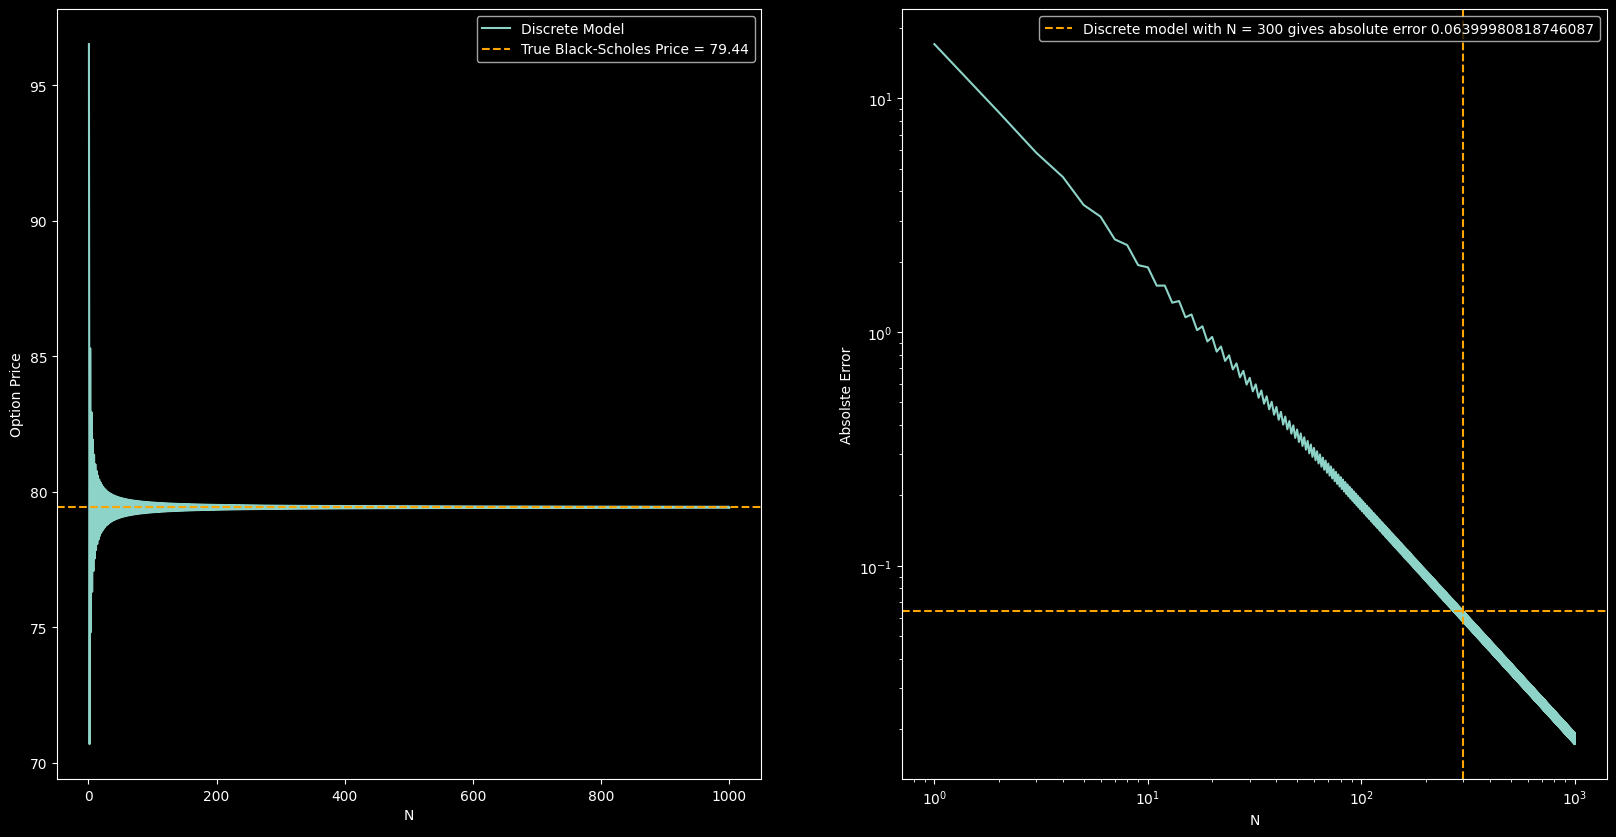

In [11]:
# Make sure option NOT American put
assert(european or call)

# Our baseline Black-Scholes price that are discrete model should converge to as N increases
true_V = black_scholes_price(S=S,K=K,r=r,T=T,sigma=sigma,call=call)

# Maximum value of N; keep under 1000 for binomial coefficient computation overflow
maxN = 1000

# Setup plotting
plt.style.use('dark_background')
fig,ax = plt.subplots(1,2,figsize=(20,10))

# Generate our X_data which is N-values, and Y_data containing our option prices
X_data = np.array(range(1,maxN+1))
Y_data = np.zeros(maxN)

if call: g = call_payoff
else: g = put_payoff

for i in range(1,maxN+1):
    R = np.exp(r*T/i)
    u = np.exp(sigma*np.sqrt(T/i))
    d = 1/u
    q = (R-d)/(u-d)
    Y_data[i-1] = 1.0/R**i * np.sum([(binom(i,j) * q**j * (1-q)**(i-j) * g(K, S * u**j * d**(i-j))) for j in range(i+1)])

# Show convergence of discrete model to continuous model
ax[0].plot(X_data,Y_data,label="Discrete Model")
ax[0].axhline(y=true_V, color="orange",linestyle="--",label=f"True Black-Scholes Price = {true_V:.2f}")
ax[0].set_xlabel("N")
ax[0].set_ylabel("Option Price")
ax[0].legend()

# Show how the absolte error changes vs N
Y_data = np.abs(Y_data - true_V)
ax[1].plot(X_data,Y_data)
ax[1].axvline(x=N,color="orange",linestyle="--",label=f"Discrete model with N = {N} gives absolute error {abs(true_V-A.V0)}")
ax[1].axhline(y=abs(true_V-A.V0),color="orange",linestyle="--")
ax[1].legend()
ax[1].set_yscale("log")
ax[1].set_xscale("log")
ax[1].set_xlabel("N")
ax[1].set_ylabel("Absolste Error")

## *Why American-style Calls Never Benefit from Early Exercising

From the tree model, suppose that one node does benefit from early exercising. For American-style call options, the value of the option at this node is given by:

$$V=\max\left(g(S),\frac{1}{R}\left(q(Su)+(1-q)(Sd)\right)\right)$$

where $g(S)=\max(S-K,0)$ is the pay-off of the call option at stock price $S$. Recall that $q$ (the risk-neutral probability) is defined by $q:=\frac{R-d}{u-d}$. So, $\frac{1}{R}\left(q(Su)+(1-q)(Sd)\right)$ ends up equating to $S$. So, 

$$V=\max(g(S),S)$$

and since we assumed that this node benefits from early exercising, we have that $g(S)>S$ implying that $S-K>S\implies K<0$ which is nonsense as strike prices are positive. So, a contradiction arises, concluding that American-style call options can never benefit from early exercising under this model.